# 01 · DQN

Ejercicios 1 a 3 del enunciado para DQN. El algoritmo está en `common/dqn.py`; aquí se comprueba que aprende, se ajusta y se analiza. Las decisiones están en `docs/DECISIONES.md`.

| § | Pregunta |
|---|---|
| 1 | ¿Cómo está diseñado el agente? |
| 2 | ¿Aprende, antes de gastar horas en barridos? |
| 3 | ¿Qué hiperparámetros elegimos en cada mercado? |
| 4 | ¿Qué consigue en test? |
| 5 | ¿Es la estrategia esperada? |
| 6 | ¿Cuánto tarda en converger? |
| 7 | ¿Se puede mejorar? |
| 8 | ¿Qué funciona, qué no y por qué? |

Todos los entrenamientos pasan por `run_grid` y quedan en caché: volver a ejecutar el notebook no repite el test.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from common.agents import BUY, HOLD, RULES, SELL, baseline_agents, evaluate_reference
from common.dqn import DQNAgent, entrena_y_evalua, evalua_modelos
from common.env import SimpleTradingEnv
from common.markets import MARKETS, make_prices
from common.protocol import (N_SEEDS_FINAL, N_STEPS, RESULTS_DIR, VAL_SEED_OFFSET, aggregate_seeds, evaluate,
                             recompute_convergence, run_episode, run_grid, save_results)
from common.style import AGENT_COLORS, MARKET_COLORS, MARKET_LABELS, POSITION_COLORS, formato, log_axis, savefig, setup
from common.tuning import Ajuste, margen_log, mejora_de_verdad, ventaja_emparejada

setup()

MERCADOS = list(MARKETS)
SEMILLAS_AJUSTE = [0, 1, 2]
N_JOBS = 6  # cada proceso carga PyTorch: con 11, el equipo se queda sin memoria
# Punto de partida. Todas las claves van explícitas para que la caché identifique cada configuración.
BASE = {"split": "val", "lr": 1e-3, "gamma": 0.9, "epsilon_decay": 0.995, "n_episodes": 500, "use_target": True,
        "normalize_obs": True, "normalize_reward": True}

## 1. Diseño

Cada elección se justifica en `docs/DECISIONES.md` (D-2.2); lo que se ajusta está en el §3.

| Pieza | Elección | Por qué |
|---|---|---|
| Entrada | `[tendencia / σ, posición]` | La tendencia real es 25 veces menor que la posición (D-1.1) |
| Red | 2 → 64 ReLU → 3 lineales | Simplificar, como pide el profesor; la salida es lineal porque Q es una regresión |
| Recompensa | `r / σ del retorno` | Escala por mercado, sin cambiar la política óptima (D-1.1) |
| Fin de episodio | Terminal: `y = r` | D-1.2 |
| Memoria | 20 000 transiciones, unos 40 episodios; empieza a entrenar con 1 000 | Valor de clase |
| Minibatch y pérdida | 128 transiciones, MSE, Adam | Valores de clase |
| Frecuencia | Un paso de gradiente cada 4 de entorno | Un tercio del coste que hacerlo en cada paso (notebook 00, §7) |
| Red objetivo | Copia cada 500 pasos, unas 2 veces por episodio | Pensada para estabilizar el objetivo; el §3 no demuestra que ayude ni que perjudique |
| Exploración | ε parte de 1 y se multiplica por 0,995 en cada episodio: acaba en 0,08 con 500 episodios, sin llegar al mínimo de 0,01 | Se ajusta en el §3 |

El agente usa su propio generador aleatorio, porque `make_prices` reinicia el de NumPy con cada serie.

## 2. Prueba rápida

Antes de los barridos, ¿aprende en los dos mercados con señal? Se prueba con 300 y 500 episodios, 3 semillas y las 100 series de validación. La referencia es la mejor regla simple en validación: x780 en el mercado 1 y +31,5 % en el 3 (`results/00_grid_reglas.csv`).

In [2]:
configs = [{**BASE, "mercado": m, "seed": s, "n_episodes": n}
           for m in ("tendencia_ciclo", "reversion_media") for n in (300, 500) for s in SEMILLAS_AJUSTE]
prueba, _ = run_grid(configs, entrena_y_evalua, "01_grid_prueba", n_jobs=N_JOBS)
tabla = prueba.pivot_table(index=["mercado", "n_episodes"], columns="seed", values="retorno_mediana")
tabla.insert(0, "mediana", tabla.median(axis=1))
display(tabla.style.format(formato))

**Sí aprende, y 500 episodios dan mucho más que 300 en el mercado 3:** +31,4 % frente a +4,6 %, con las tres semillas de acuerdo. En el mercado 1 la mediana sube de x381,5 a x505,5, con menos dispersión. Ojo: con 300 episodios ε acaba en 0,22 y con 500, en 0,08, así que esta prueba no separa el efecto de entrenar más del de explorar menos.

Las dos referencias siguen por encima o empatadas: x780 en el mercado 1 y +31,5 % en el 3.

## 3. Ajuste de hiperparámetros (ejercicio 3)

Por etapas, un parámetro cada vez y por mercado, como en el Taller 1. Todo se mide en las 100 series de validación, con 3 semillas: la puntuación es la mediana entre semillas de la mediana por serie.

**Un valor nuevo solo sustituye al actual si mejora más que el ruido.** Son unos 2 errores estándar de la mediana con 100 series (notebook 00, §5): 10 puntos en los mercados 2 y 4, 2 puntos en el 3 y un 25 % del múltiplo en el 1. Sin esta regla, en los mercados sin señal se elegiría el azar más favorable (D-2.3).

In [3]:
ajuste = Ajuste(BASE, MERCADOS, SEMILLAS_AJUSTE, entrena_y_evalua, "01", N_JOBS)
ACTUAL, PUNTOS, etapa = ajuste.actual, ajuste.puntos, ajuste.etapa

### Normalización: confirmar D-1.1 con el DQN definitivo

D-1.1 se decidió con un DQN mínimo cuyo código no está en el repositorio. Aquí se repite la comparación con este agente y en los 4 mercados.

In [4]:
VARIANTES = {"nada": (False, False), "solo recompensa": (False, True), "solo observación": (True, False), "las dos": (True, True)}
configs = [{**BASE, "mercado": m, "seed": s, "normalize_obs": o, "normalize_reward": r}
           for m in MERCADOS for o, r in VARIANTES.values() for s in SEMILLAS_AJUSTE]
normalizacion, _ = run_grid(configs, entrena_y_evalua, "01_grid_normalizacion", n_jobs=N_JOBS)
puntos = normalizacion.groupby(["mercado", "normalize_obs", "normalize_reward"]).retorno_mediana.median()
tabla = pd.DataFrame({MARKET_LABELS[m]: {v: puntos[m, o, r] for v, (o, r) in VARIANTES.items()} for m in MERCADOS}).T
display(tabla.style.format(formato).set_caption("Mediana en validación, según qué se normaliza"))
operaciones = normalizacion.groupby(["mercado", "normalize_obs", "normalize_reward"]).n_trades.median()
display(pd.DataFrame({MARKET_LABELS[m]: {v: operaciones[m, o, r] for v, (o, r) in VARIANTES.items()} for m in MERCADOS}).T
        .style.format("{:.1f}").set_caption("Operaciones por episodio"))
PUNTOS.update({m: puntos[m, True, True] for m in MERCADOS})

,nada,solo recompensa,solo observación,las dos
1 · Tendencia + ciclo,x370.0,x528.5,x596.6,x505.5
2 · Browniano geométrico,+0.0%,+0.0%,+0.0%,-1.6%
3 · Reversión a la media,+2.3%,+28.8%,+29.3%,+31.4%
4 · Regímenes,+0.0%,+0.0%,+0.0%,+0.0%


,nada,solo recompensa,solo observación,las dos
1 · Tendencia + ciclo,60.1,60.7,51.3,56.9
2 · Browniano geométrico,0.0,1.0,1.7,1.8
3 · Reversión a la media,3.3,42.9,27.2,33.4
4 · Regímenes,0.1,0.0,1.2,0.0


**Hay que normalizar, pero no se puede decir que hacer las dos cosas sea lo mejor.** En el mercado 3, sin normalizar nada solo se obtiene +2,3 %, con 3,3 operaciones: casi no opera, como se temía en D-1.1. Normalizar una de las dos cosas ya sube a +28,8 % o +29,3 %, y las dos, a +31,4 %. Esa última diferencia queda justo en el margen de ruido, aunque "las dos" es la única variante sin ninguna semilla mala (solo la observación da +1,8 % en la semilla 2).

En el mercado 1, sin nada se queda en x370, y las otras tres se solapan (x505-x597). En los mercados 2 y 4 no se distingue nada. Se mantiene la decisión de D-1.1 con esta evidencia.

### Red objetivo, α, γ, ε y número de episodios

In [5]:
etapa("objetivo", "use_target", [True, False])

,False,True
1 · Tendencia + ciclo,x410.5,x505.5
2 · Browniano geométrico,-0.8%,-1.6%
3 · Reversión a la media,+30.8%,+31.4%
4 · Regímenes,-7.1%,+0.0%


,False,True
1 · Tendencia + ciclo,409.535345,504.501029
2 · Browniano geométrico,-0.008008,-0.016111
3 · Reversión a la media,0.307565,0.313749
4 · Regímenes,-0.070779,0.000000


In [6]:
etapa("lr", "lr", [1e-4, 3e-4, 1e-3])

,0.000100,0.000300,0.001000
1 · Tendencia + ciclo,x585.7,x405.4,x505.5
2 · Browniano geométrico,+0.3%,+0.0%,-1.6%
3 · Reversión a la media,+19.9%,+23.0%,+31.4%
4 · Regímenes,+0.0%,-15.9%,+0.0%


,0.0001,0.0003,0.0010
1 · Tendencia + ciclo,584.681489,404.430243,504.501029
2 · Browniano geométrico,0.003264,0.000000,-0.016111
3 · Reversión a la media,0.199450,0.230097,0.313749
4 · Regímenes,0.000000,-0.159467,0.000000


In [7]:
etapa("gamma", "gamma", [0.0, 0.5, 0.9, 0.99])

,0.000000,0.500000,0.900000,0.990000
1 · Tendencia + ciclo,x561.6,x488.3,x505.5,x212.2
2 · Browniano geométrico,+0.0%,+2.7%,-1.6%,+0.1%
3 · Reversión a la media,+32.8%,+31.4%,+31.4%,+19.6%
4 · Regímenes,-4.7%,-6.7%,+0.0%,-6.4%


,0.00,0.50,0.90,0.99
1 · Tendencia + ciclo,560.608964,487.344274,504.501029,211.245297
2 · Browniano geométrico,0.000000,0.026580,-0.016111,0.000577
3 · Reversión a la media,0.327668,0.313520,0.313749,0.196454
4 · Regímenes,-0.046682,-0.067404,0.000000,-0.064079


In [8]:
etapa("epsilon", "epsilon_decay", [0.98, 0.99, 0.995])

,0.980000,0.990000,0.995000
1 · Tendencia + ciclo,x583.6,x542.4,x505.5
2 · Browniano geométrico,-7.8%,-0.4%,-1.6%
3 · Reversión a la media,+26.4%,+24.0%,+31.4%
4 · Regímenes,+0.0%,+0.0%,+0.0%


,0.980,0.990,0.995
1 · Tendencia + ciclo,582.617561,541.405279,504.501029
2 · Browniano geométrico,-0.078049,-0.003918,-0.016111
3 · Reversión a la media,0.264217,0.239787,0.313749
4 · Regímenes,0.000000,0.000000,0.000000


In [9]:
etapa("episodios", "n_episodes", [300, 500, 1000])

,300,500,1000
1 · Tendencia + ciclo,x381.5,x505.5,x515.7
2 · Browniano geométrico,+1.0%,-1.6%,-2.6%
3 · Reversión a la media,+4.6%,+31.4%,+20.6%
4 · Regímenes,-10.6%,+0.0%,-3.2%


,300,500,1000
1 · Tendencia + ciclo,380.512401,504.501029,514.706273
2 · Browniano geométrico,0.009787,-0.016111,-0.026033
3 · Reversión a la media,0.046437,0.313749,0.206380
4 · Regímenes,-0.106171,0.000000,-0.032026


In [10]:
ELEGIDOS = pd.DataFrame({MARKET_LABELS[m]: {k: ACTUAL[m][k] for k in ("use_target", "lr", "gamma", "epsilon_decay", "n_episodes")} | {"mediana en validación": formato(PUNTOS[m])}
                         for m in MERCADOS}).T
ELEGIDOS

,use_target,lr,gamma,epsilon_decay,n_episodes,mediana en validación
1 · Tendencia + ciclo,True,0.001,0.9,0.995,500,x505.5
2 · Browniano geométrico,True,0.001,0.9,0.995,500,-1.6%
3 · Reversión a la media,True,0.001,0.9,0.995,500,+31.4%
4 · Regímenes,True,0.001,0.9,0.995,500,+0.0%


**Ningún cambio supera el margen de ruido en ningún mercado, así que los cuatro se quedan con la configuración de partida.** Esto no prueba que sea la mejor: solo que, con 3 semillas y un parámetro cada vez, no se distingue de las alternativas.

| Parámetro | Qué se ve |
|---|---|
| Red objetivo | Sin ella: x410,5 frente a x505,5 en el 1, +30,8 % frente a +31,4 % en el 3 y −7,1 % frente a 0 % en el 4. Todo dentro del ruido: no se demuestra su utilidad |
| α | Sin patrón: en el 1, 3e-4 da x405 y 1e-4, x586, por encima de los x505 de 1e-3. En el 3, bajar α perjudica (+19,9 % y +23,0 % frente a +31,4 %) |
| γ | **0,99 es claramente peor** donde hay señal (x212 y +19,6 %). Entre 0 y 0,9 apenas cambia (x489-x562 y +31,4-32,8 %), como en el Taller 1: el horizonte corto basta |
| ε | Decaer más rápido no ayuda en el 3 (+26,4 % y +24,0 %) y en el 1 no pasa del margen (x584 y x542) |
| Episodios | 300 son pocos (+4,6 % y x381), pero 1 000 no mejoran (+20,6 % y x516) |

Los dos últimos están ligados, porque con el mismo decaimiento más episodios también significa menos exploración al final. Por tiempo, aquí no se ajustan juntos: es una limitación que hay que declarar.

## 4. Resultado final en test (ejercicios 1 y 4)

Una sola vez, con los hiperparámetros elegidos y `N_SEEDS_FINAL` semillas. Se ejecuta en un solo proceso porque `tiempo_s` solo es comparable así. El 04 lee `results/01_dqn.csv`, con una fila por mercado (mediana entre semillas); el detalle por semilla queda en `results/01_grid_final.csv`.

In [11]:
configs = [{**ACTUAL[m], "split": "test", "mercado": m, "seed": s, "guardar": f"dqn_{m}_s{s}"}
           for m in MERCADOS for s in range(N_SEEDS_FINAL)]
final, curvas = run_grid(configs, entrena_y_evalua, "01_grid_final", n_jobs=1)
final = recompute_convergence(final, curvas)
final.to_csv(RESULTS_DIR / "01_grid_final.csv", index=False)
resumen = save_results(aggregate_seeds(final.to_dict("records")), "01_dqn")
CURVAS = {m: [curvas[i] for i in final[final.mercado == m].id] for m in MERCADOS}

referencias = pd.read_csv(RESULTS_DIR / "00_baselines.csv")
tabular = pd.read_csv(RESULTS_DIR / "taller1_tabular.csv")
tabular = tabular[tabular.agente.isin(["qlearning", "sarsa"])]
todo = pd.concat([referencias, tabular, resumen], ignore_index=True)
orden = [a for a in AGENT_COLORS if a in set(todo.agente)]
tabla = todo.pivot(index="agente", columns="mercado", values="retorno_mediana").loc[orden, MERCADOS]
display(tabla.style.highlight_max(props="background-color: #E3F4EA; font-weight: bold").format(formato)
        .format_index(lambda m: MARKET_LABELS[m], axis=1).set_caption("Mediana del retorno en las 200 series de test"))

por_semilla = final.pivot(index="mercado", columns="seed", values="retorno_mediana").loc[MERCADOS].rename(index=MARKET_LABELS)
display(por_semilla.style.format(formato).set_caption("DQN en test, por semilla: la dispersión que esconde la mediana"))
metricas = resumen.set_index("mercado").loc[MERCADOS, ["retorno_medio", "std", "sharpe", "max_drawdown", "n_trades", "tiempo_s"]].rename(index=MARKET_LABELS)
display(metricas.style.format({"retorno_medio": "{:+.1%}", "std": "{:.1%}", "sharpe": "{:+.3f}", "max_drawdown": "{:.1%}", "n_trades": "{:.1f}", "tiempo_s": "{:.0f}"}))

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
agente,,,,
aleatorio,x4.3,-19.4%,-17.2%,-22.0%
buy_hold,x33.6,-3.5%,-0.3%,-12.5%
no_operar,+0.0%,+0.0%,+0.0%,+0.0%
regla_tendencia,x630.4,-4.4%,-22.3%,-10.5%
regla_reversion,-50.1%,-4.8%,+29.2%,-10.6%
qlearning,x502.3,+0.0%,+27.0%,+0.0%
sarsa,x471.6,+0.0%,+27.0%,+0.0%
dqn,x299.8,-3.9%,+20.5%,+0.0%


seed,0,1,2,3,4
mercado,,,,,
1 · Tendencia + ciclo,x299.8,x263.6,x228.4,x305.3,x557.8
2 · Browniano geométrico,-3.9%,-6.4%,-6.0%,+0.0%,-3.6%
3 · Reversión a la media,+26.3%,+24.0%,+20.5%,+4.7%,+16.8%
4 · Regímenes,+0.0%,-7.9%,+0.0%,-3.7%,+0.0%


,retorno_medio,std,sharpe,max_drawdown,n_trades,tiempo_s
mercado,,,,,,
1 · Tendencia + ciclo,+124283.0%,278561.1%,+0.169,73.5%,52.8,66
2 · Browniano geométrico,+0.7%,44.5%,+0.000,40.7%,1.6,66
3 · Reversión a la media,+23.6%,24.4%,+0.035,21.4%,32.7,66
4 · Regímenes,-0.1%,0.9%,-0.001,0.2%,0.1,66


¿Bate de verdad a la mejor referencia? Comparar medianas ignora que el ruido del mercado es común. Aquí se compara **serie a serie**, sobre las mismas 200 series de test y en escala logarítmica, con la mejor referencia de cada mercado: `regla_tendencia` en el 1, `no_operar` en el 2 y el 4, y `regla_reversion` en el 3.

In [12]:
REFERENCIA = {"tendencia_ciclo": "regla_tendencia", "browniano": "no_operar", "reversion_media": "regla_reversion", "regimenes": "no_operar"}
umbrales = pd.read_csv(RESULTS_DIR / "00_grid_referencias.csv").set_index(["agente", "mercado"]).umbral
filas = {}
for m in MERCADOS:
    nombre = REFERENCIA[m]
    agente = RULES[nombre](umbrales[nombre, m]) if nombre in RULES else baseline_agents()[nombre]
    ref = np.log1p(evaluate(agente, m)["retorno"].to_numpy())
    dif = np.array([np.log1p(c["eval_retornos"]) - ref for c in CURVAS[m]])
    por_seed = np.median(dif, axis=1)
    filas[MARKET_LABELS[m]] = {"referencia": nombre, "ventaja mediana (log)": np.median(por_seed), "mín. entre semillas": por_seed.min(),
                               "máx. entre semillas": por_seed.max(), "gana": (dif > 1e-9).mean(), "empata": (np.abs(dif) <= 1e-9).mean(), "pierde": (dif < -1e-9).mean()}
display(pd.DataFrame(filas).T.style.format({"ventaja mediana (log)": "{:+.3f}", "mín. entre semillas": "{:+.3f}", "máx. entre semillas": "{:+.3f}", "gana": "{:.0%}", "empata": "{:.0%}", "pierde": "{:.0%}"}))

,referencia,ventaja mediana (log),mín. entre semillas,máx. entre semillas,gana,empata,pierde
1 · Tendencia + ciclo,regla_tendencia,-0.675,-0.888,-0.149,26%,0%,74%
2 · Browniano geométrico,no_operar,-0.040,-0.067,+0.000,35%,20%,44%
3 · Reversión a la media,regla_reversion,-0.060,-0.193,-0.000,37%,0%,63%
4 · Regímenes,no_operar,+0.000,-0.083,+0.000,17%,59%,24%


**DQN bate a buy & hold y al aleatorio donde hay señal, pero no a las reglas simples ni a los tabulares del Taller 1.**

- **Mercado 1:** x299,8 frente a x630,4 de la regla, x502,3 de Q-Learning y x33,6 de buy & hold. Serie a serie, gana a la regla en el 26 % de las series, y su ventaja mediana es de −0,675 en logaritmo: acaba con la mitad de capital.
- **Mercado 3:** +20,5 % frente a +29,2 % de la regla y +27,0 % de Q-Learning. La semilla 3 se queda en +4,7 %.
- **Mercados 2 y 4:** en los dos, lo mejor sigue siendo no operar. En el 2 pierde un 3,9 %, similar a buy & hold (−3,5 %), y en el 4 tres semillas no operan, pero dos pierden un 7,9 % y un 3,7 %.

**El resultado es sólido:** en 400 series que no se han usado para nada (§7), los mismos modelos dan x287,4, −6,1 %, +24,5 % y 0 %. La caída frente a validación se explica en parte porque esas series son más favorables (la regla también baja de x780 a x630). En el mercado 3, el +31,4 % de validación venía además de 3 semillas afortunadas: con las 5 es +27,7 % (§7).

## 5. Estrategia aprendida en cada mercado (ejercicio 2)

¿Es la esperada? La figura muestra lo que ha aprendido cada semilla: **la ventaja de operar frente a no hacer nada**, según la tendencia. Arriba, sin activo: comprar menos mantener. Abajo, con activo: vender menos mantener. Por encima de cero, la política opera.

Lo esperado (notebook 00, §4): seguir la tendencia en el 1, no operar en el 2, comprar tras caídas y vender tras subidas en el 3, y no operar en el 4.

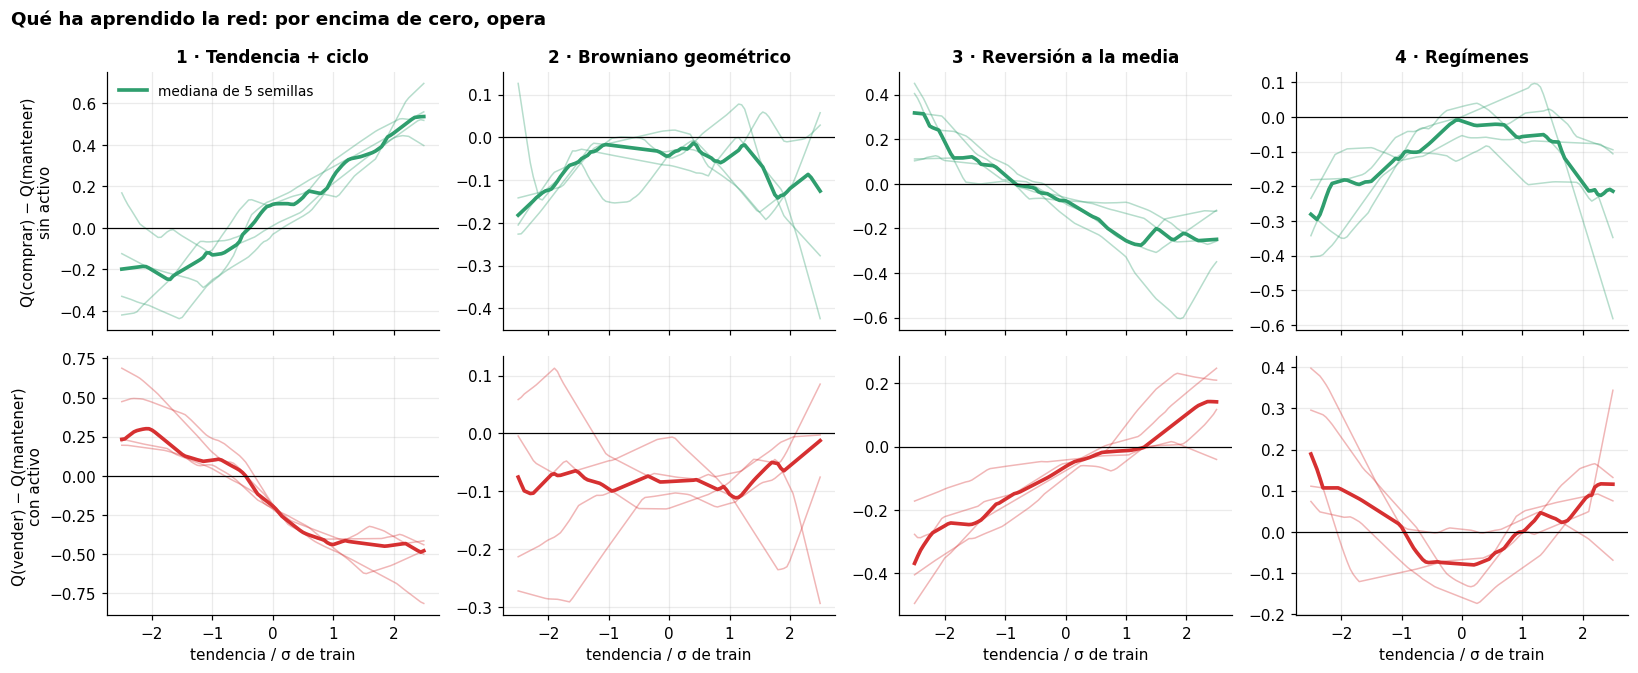

,|Q| entre acciones iguales,|Q| de operar frente a mantener
1 · Tendencia + ciclo,0.081,0.275
2 · Browniano geométrico,0.037,0.089
3 · Reversión a la media,0.045,0.145
4 · Regímenes,0.045,0.105


In [13]:
K = np.linspace(-2.5, 2.5, 101)
AGENTES = {m: [DQNAgent.load(f"dqn_{m}_s{s}") for s in range(N_SEEDS_FINAL)] for m in MERCADOS}


def q_rejilla(agente, posicion):
    tendencias = K * agente.scales[0]
    return np.array([agente.q_values(np.array([t, posicion], dtype=np.float32)) for t in tendencias])


fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True)
filas = {}
for j, m in enumerate(MERCADOS):
    comprar, vender, redundante, util = [], [], [], []
    for agente in AGENTES[m]:
        q0, q1 = q_rejilla(agente, 0), q_rejilla(agente, 1)
        comprar.append(q0[:, BUY] - q0[:, HOLD])
        vender.append(q1[:, SELL] - q1[:, HOLD])
        redundante.append(np.r_[np.abs(q0[:, SELL] - q0[:, HOLD]), np.abs(q1[:, BUY] - q1[:, HOLD])].mean())
        util.append(np.r_[np.abs(comprar[-1]), np.abs(vender[-1])].mean())
    for ax, curvas_q, color in ((axes[0, j], comprar, POSITION_COLORS[1]), (axes[1, j], vender, POSITION_COLORS[0])):
        for c in curvas_q:
            ax.plot(K, c, color=color, alpha=0.35, lw=1)
        ax.plot(K, np.median(curvas_q, axis=0), color=color, lw=2.4, label="mediana de 5 semillas")
        ax.axhline(0, color="black", lw=0.8)
    axes[0, j].set_title(MARKET_LABELS[m])
    axes[1, j].set_xlabel("tendencia / σ de train")
    filas[MARKET_LABELS[m]] = {"|Q| entre acciones iguales": np.mean(redundante), "|Q| de operar frente a mantener": np.mean(util)}
axes[0, 0].set_ylabel("Q(comprar) − Q(mantener)\nsin activo")
axes[1, 0].set_ylabel("Q(vender) − Q(mantener)\ncon activo")
axes[0, 0].legend()
fig.suptitle("Qué ha aprendido la red: por encima de cero, opera", x=0.01, ha="left", weight="bold")
fig.tight_layout()
savefig(fig, "01_politica")
plt.show()
display(pd.DataFrame(filas).T.style.format("{:.3f}").set_caption("Comprobación: dos acciones iguales deberían valer casi lo mismo (en unidades de recompensa escalada)"))

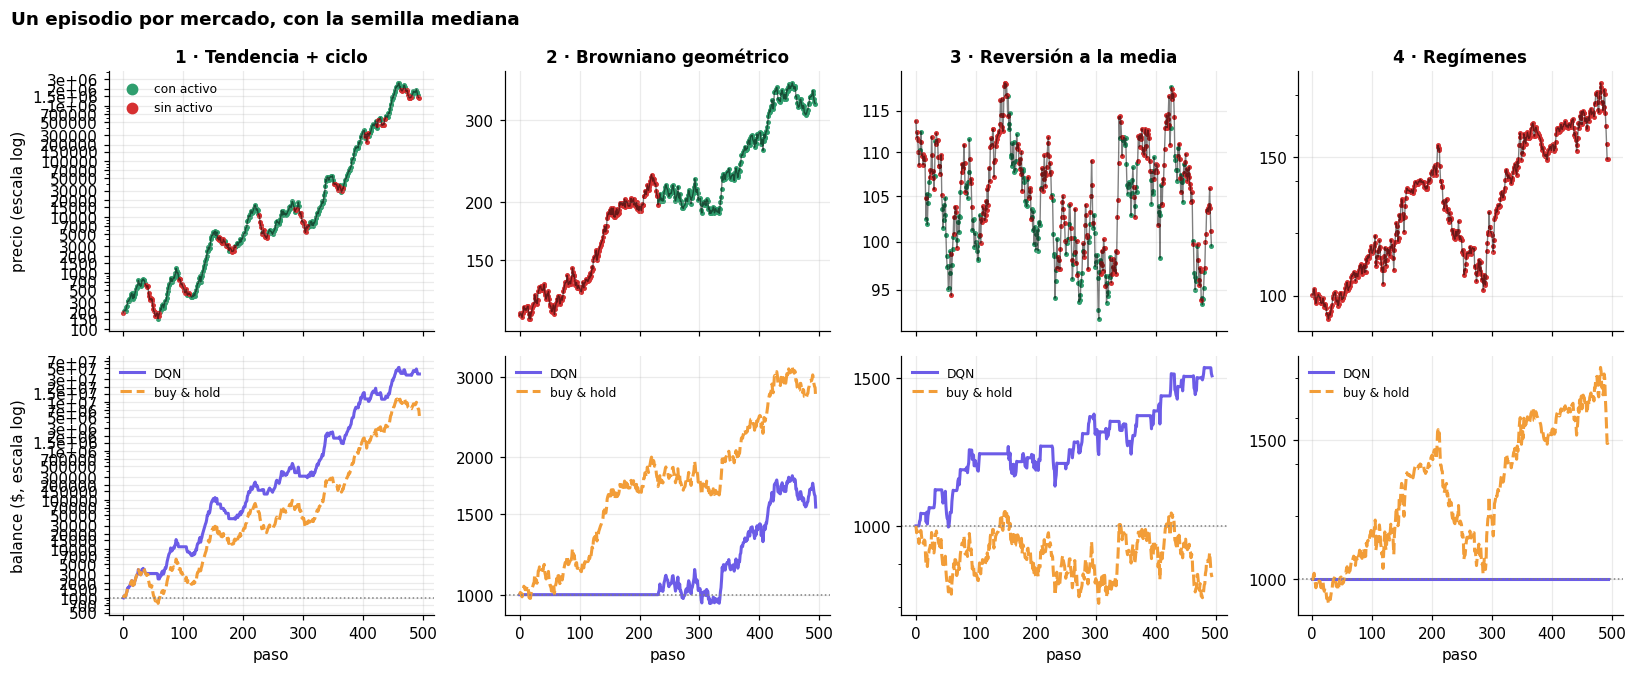

,tiempo con activo,operaciones en test
1 · Tendencia + ciclo,73%,52.8
2 · Browniano geométrico,72%,1.6
3 · Reversión a la media,63%,32.7
4 · Regímenes,28%,0.1


In [14]:
SERIE = VAL_SEED_OFFSET  # primera serie de validación: el test ya se ha usado
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True)
filas = {}
for j, m in enumerate(MERCADOS):
    orden_semillas = np.argsort(final[final.mercado == m].retorno_mediana.to_numpy())
    agente = AGENTES[m][orden_semillas[len(orden_semillas) // 2]]  # la semilla mediana, no la mejor
    precios = make_prices(m, N_STEPS, SERIE)
    _, balance, _, posicion = run_episode(SimpleTradingEnv(precios), agente)
    validos = precios[5:-1]
    ax = axes[0, j]
    ax.plot(validos, color="black", lw=0.9, alpha=0.5)
    log_axis(ax)
    ax.scatter(np.flatnonzero(posicion == 1), validos[posicion == 1], s=5, color=POSITION_COLORS[1], label="con activo")
    ax.scatter(np.flatnonzero(posicion == 0), validos[posicion == 0], s=5, color=POSITION_COLORS[0], label="sin activo")
    ax.set_title(MARKET_LABELS[m])
    ax = axes[1, j]
    ax.plot(balance, color=AGENT_COLORS["dqn"], lw=2, label="DQN")
    ax.plot(run_episode(SimpleTradingEnv(precios), baseline_agents()["buy_hold"])[1], color=AGENT_COLORS["buy_hold"], lw=2, ls="--", label="buy & hold")
    ax.axhline(1000, color="gray", ls=":", lw=1)
    log_axis(ax)
    ax.set_xlabel("paso")
    ax.legend(fontsize=8)
    # Tiempo dentro en 20 series de validación, con las 5 semillas
    dentro = [run_episode(SimpleTradingEnv(make_prices(m, N_STEPS, VAL_SEED_OFFSET + i)), a)[3].mean() for a in AGENTES[m] for i in range(20)]
    filas[MARKET_LABELS[m]] = {"tiempo con activo": np.mean(dentro), "operaciones en test": resumen.set_index("mercado").n_trades[m]}
axes[0, 0].set_ylabel("precio (escala log)")
axes[0, 0].legend(fontsize=8, markerscale=3)
axes[1, 0].set_ylabel("balance ($, escala log)")
fig.suptitle("Un episodio por mercado, con la semilla mediana", x=0.01, ha="left", weight="bold")
fig.tight_layout()
savefig(fig, "01_episodios")
plt.show()
display(pd.DataFrame(filas).T.style.format({"tiempo con activo": "{:.0%}", "operaciones en test": "{:.1f}"}))

**La estrategia es la esperada en los mercados 1, 3 y, en parte, 4. En el 2 no lo es.**

| Mercado | Esperada | Encontrada |
|---|---|---|
| 1 · Tendencia | Seguir la tendencia | **Sí.** Compra con tendencia positiva y vende con negativa, en las 5 semillas |
| 2 · Browniano | No operar | **No.** Casi no opera (1,6 operaciones), pero entra y se queda: 72 % del tiempo con el activo. Solo una semilla se queda fuera |
| 3 · Reversión | Comprar tras caídas y vender tras subidas | **Sí.** Las curvas tienen la pendiente correcta, con umbrales cerca de ±1 σ. La semilla 3 casi no vende (5,9 operaciones) |
| 4 · Regímenes | No operar | **En parte.** Tres semillas no operan; las otras dos hacen unas 74 operaciones y pierden |

**Tres cosas que no se ven en la tabla de resultados:**

1. **En el mercado 1, más operaciones significan menos retorno en las 5 semillas:** 44 operaciones dan x558; 49, x305; 53, x300; 60, x264; y 69, x228. La regla hace 41. La comisión, escalada, vale 0,009 frente a un ruido de 1 por paso, así que a la red le cuesta aprender a no operar de más.
2. **En el mercado 2, la recompensa no mide lo mismo que el balance.** El retorno simple esperado por paso es +0,0001, pero el logarítmico, que es el que manda en el capital, es −0,0001. Para la recompensa del entorno, quedarse dentro sale a cuenta aunque en mediana se pierda. Explica por qué entra y no sale.
3. **En el mercado 4, con activo vende ante movimientos grandes en cualquier sentido** (forma de U). Es la no linealidad que anticipaba el notebook 00, §4: los movimientos grandes delatan el régimen bajista. Lo aprende una red y no una regla lineal, aunque no basta para ganar.

**Señal de alarma:** dos acciones que hacen lo mismo deberían valer igual, y su diferencia en Q es del 30-43 % de la que separa operar de mantener (tabla del principio). Parte de lo que decide la política es ruido de la red. El §7 lo ataca directamente.

## 6. Convergencia (ejercicio 4)

Las dos curvas de D-0.3, con el retorno sobre el balance para que sean comparables:

- **Con exploración:** el retorno de cada episodio de entrenamiento, con ε activo (mediana móvil de 25 episodios). Es lo que hace el agente mientras aprende.
- **Sin exploración:** la política greedy cada 25 episodios, en 20 series de validación fijas. Es lo que sabe hacer.

Parte de la distancia entre ambas es ruido, porque usan series distintas y la segunda solo tiene 20.

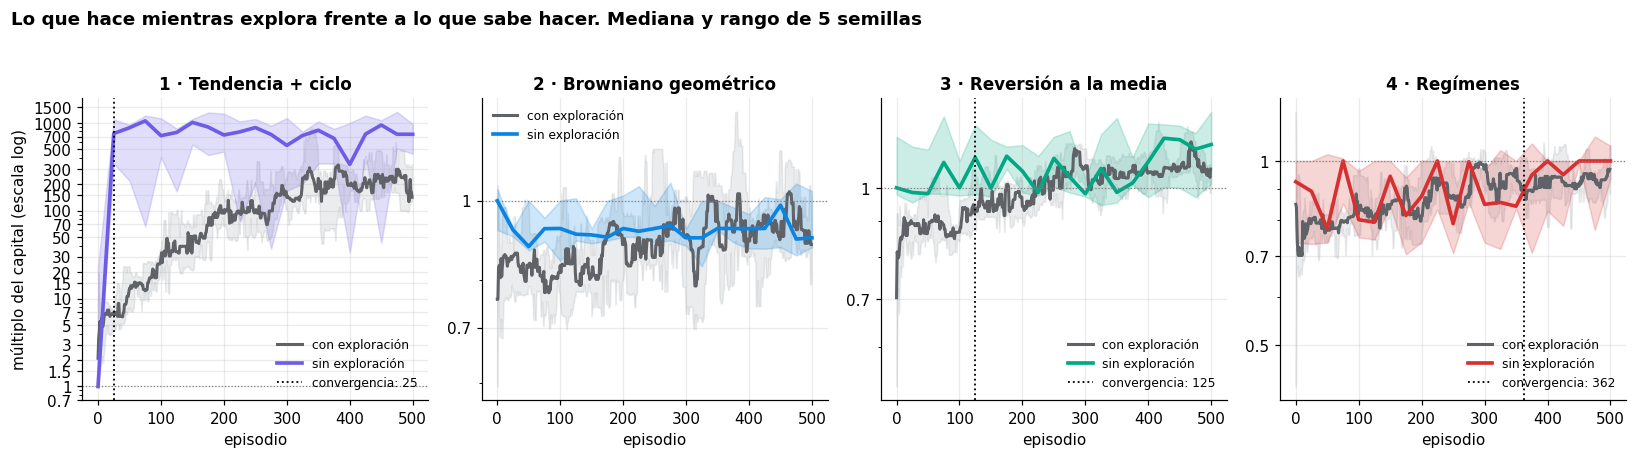

,semillas que convergen,episodios,pasos de entorno,segundos,criterio del Taller 1 (episodios),entrenamiento total (s)
1 · Tendencia + ciclo,5 de 5,25,12350,3,314,66
2 · Browniano geométrico,0 de 5,ninguna,ninguna,ninguna,297,66
3 · Reversión a la media,5 de 5,125,61750,15,280,66
4 · Regímenes,2 de 5,362,179075,47,293,66


estado_convergencia,converge,no mejora,no opera
mercado,,,
1 · Tendencia + ciclo,5,0,0
2 · Browniano geométrico,0,4,1
3 · Reversión a la media,5,0,0
4 · Regímenes,2,0,3


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharex=False)
for ax, m in zip(axes, MERCADOS):
    curvas_m = CURVAS[m]
    con = np.array([pd.Series(1 + c["retorno"]).rolling(25, min_periods=1).median() for c in curvas_m])
    sin = 1 + np.array([c["val_retorno"] for c in curvas_m])
    x = np.arange(con.shape[1])
    ax.fill_between(x, con.min(axis=0), con.max(axis=0), color="#9AA0A6", alpha=0.2)
    ax.plot(x, np.median(con, axis=0), color="#5F6368", lw=2, label="con exploración")
    e = curvas_m[0]["val_episodios"]
    ax.fill_between(e, sin.min(axis=0), sin.max(axis=0), color=MARKET_COLORS[m], alpha=0.2)
    ax.plot(e, np.median(sin, axis=0), color=MARKET_COLORS[m], lw=2.4, label="sin exploración")
    conv = resumen.set_index("mercado").episodios_convergencia[m]
    if np.isfinite(conv):
        ax.axvline(conv, color="black", ls=":", lw=1.2, label=f"convergencia: {conv:.0f}")
    ax.axhline(1, color="gray", ls=":", lw=0.8)
    log_axis(ax)
    ax.set_title(MARKET_LABELS[m])
    ax.set_xlabel("episodio")
    ax.legend(fontsize=8)
axes[0].set_ylabel("múltiplo del capital (escala log)")
fig.suptitle("Lo que hace mientras explora frente a lo que sabe hacer. Mediana y rango de 5 semillas", x=0.01, ha="left", weight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "01_dos_curvas")
plt.show()

tabla = final.groupby("mercado", sort=False)[["episodios_convergencia", "pasos_convergencia", "tiempo_convergencia_s", "episodios_convergencia_taller1", "tiempo_s"]].median().loc[MERCADOS]
tabla.index = [MARKET_LABELS[m] for m in MERCADOS]
tabla.columns = ["episodios", "pasos de entorno", "segundos", "criterio del Taller 1 (episodios)", "entrenamiento total (s)"]
tabla.insert(0, "semillas que convergen", [f"{(final[final.mercado == m].estado_convergencia == 'converge').sum()} de {N_SEEDS_FINAL}" for m in MERCADOS])
display(tabla.style.format("{:.0f}", na_rep="ninguna", subset=tabla.columns[1:]))
display(final.groupby("mercado", sort=False).estado_convergencia.value_counts().unstack(fill_value=0).loc[MERCADOS].rename(index=MARKET_LABELS))

**Convergencia, en la curva sin exploración (D-0.3):**

| Mercado | Semillas que convergen | Episodios | Lectura |
|---|---|---|---|
| 1 | 5 de 5 | 25 | **Aprende muy pronto**, con ε aún en 0,88, y luego no mejora |
| 2 | 0 de 5 | — | 4 no mejoran y 1 no opera: no hay nada que aprender |
| 3 | 5 de 5 | 125 | Mediana de 25 a 500 entre semillas: es lo más lento, y el mercado con menos señal de los dos |
| 4 | 2 de 5 | 362 | Solo las dos semillas que operan; las otras acaban sin operar |

**La figura muestra por qué hay que mirar las dos curvas.** En el mercado 1, el agente ya sabe a los 25 episodios lo que no se ve en su comportamiento hasta bien avanzado el entrenamiento: la curva con exploración sigue subiendo solo porque ε baja, no porque aprenda más. Es lo que advirtió el profesor (T30 ~04:41).

**La política no llega a estabilizarse.** Cambia de golpe hasta el final: en el mercado 1, semilla 0, pasa de x557 a x43 y a x744 en tres puntos seguidos; en el 3, semilla 3, de +15,2 % a +1,3 % en los últimos 25 episodios. Cada punto usa solo 20 series, pero el número de operaciones también cambia (35, 1 y 32 en la semilla 0 del mercado 3), así que es la política la que cambia, no solo el ruido. Por eso el modelo final es una foto de un momento concreto, y las cifras de convergencia hay que leerlas con cautela.

Para comparar con el Taller 1: el criterio antiguo (280-314 episodios) mide sobre la recompensa con exploración y no se puede comparar con este. Cada entrenamiento de 500 episodios tarda unos 66 s, sin contar las evaluaciones.

## 7. ¿Se puede mejorar?

Los §5 y §6 dejan tres problemas con solución barata. **El test ya se ha visto** (D-2.4), así que el resultado anterior se queda como referencia. Las mejoras se eligen solo en validación, y una mejora solo se adopta si supera el margen de ruido.

| Mejora | Problema | Evidencia |
|---|---|---|
| Acciones canónicas con Doble DQN | Ruido en acciones que hacen lo mismo y sobrestimación del `max` | Diferencia del 30-43 % entre acciones iguales (§5) |
| Recompensa logarítmica | La recompensa no mide lo mismo que el balance | Browniano: +0,0001 por paso con retorno simple y −0,0001 con logarítmico (§5) |
| Mejor punto en validación | El modelo final es una foto de un momento concreto | Mercado 3, semilla 3: de +15,2 % a +1,3 % en 25 episodios (§6) |
| Decidir con la media de las 5 redes | Dispersión entre semillas | De x228 a x558 y de +4,7 % a +26,3 % (§4) |

Con 5 semillas y **comparando en las mismas series**, semilla a semilla, con el margen de ruido de D-2.3 en logaritmo: 0,22 en el mercado 1, 0,02 en el 3 y 0,10 en el 2 y el 4.

In [16]:
VARIANTES = {"canónicas + Doble": {"double_canonical": True}, "recompensa log": {"log_reward": True}, "mejor punto": {"best_checkpoint": True}}
SEMILLAS = list(range(N_SEEDS_FINAL))


def retornos(df, curvas_df):
    return {m: [curvas_df[i]["eval_retornos"] for i in df[df.mercado == m].sort_values("seed").id] for m in df.mercado.unique()}


base_val, curvas_base = run_grid([{**BASE, "mercado": m, "seed": s} for m in MERCADOS for s in SEMILLAS], entrena_y_evalua, "01_grid_mejora_base", n_jobs=N_JOBS)
RET_BASE = retornos(base_val, curvas_base)
variantes, curvas_var = run_grid([{**BASE, **cambios, "variante": v, "mercado": m, "seed": s} for v, cambios in VARIANTES.items() for m in MERCADOS for s in SEMILLAS],
                                 entrena_y_evalua, "01_grid_mejora_variantes", n_jobs=N_JOBS)
RES = {}
for v in VARIANTES:
    ret = retornos(variantes[variantes.variante == v], curvas_var)
    for m in MERCADOS:
        ventaja, ganan = ventaja_emparejada(ret[m], RET_BASE[m])
        d = variantes[(variantes.variante == v) & (variantes.mercado == m)]
        RES[v, m] = {"ventaja": ventaja, "ganan": ganan, "mediana": d.retorno_mediana.median(), "operaciones": d.n_trades.median(), "adoptada": ventaja > margen_log(m)}

marcas = pd.DataFrame({v: {MARKET_LABELS[m]: "background-color: #E3F4EA; font-weight: bold" if RES[v, m]["adoptada"] else "" for m in MERCADOS} for v in VARIANTES}).T
display(pd.DataFrame({v: {MARKET_LABELS[m]: RES[v, m]["ventaja"] for m in MERCADOS} for v in VARIANTES}).T.style.apply(lambda _: marcas, axis=None).format("{:+.3f}")
        .set_caption("Ventaja en log frente a la base, en las mismas series de validación. En verde, supera el margen de ruido"))
display(pd.DataFrame({"base": {MARKET_LABELS[m]: formato(base_val[base_val.mercado == m].retorno_mediana.median()) for m in MERCADOS},
                      **{v: {MARKET_LABELS[m]: formato(RES[v, m]["mediana"]) for m in MERCADOS} for v in VARIANTES}}).T.style.set_caption("Mediana en validación"))
display(pd.DataFrame({"base": {MARKET_LABELS[m]: base_val[base_val.mercado == m].n_trades.median() for m in MERCADOS},
                      **{v: {MARKET_LABELS[m]: RES[v, m]["operaciones"] for m in MERCADOS} for v in VARIANTES}}).T.style.format("{:.1f}").set_caption("Operaciones por episodio"))
display(pd.DataFrame({v: {MARKET_LABELS[m]: RES[v, m]["ganan"] for m in MERCADOS} for v in VARIANTES}).T.style.set_caption("Semillas, de 5, que mejoran a la base"))

,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
canónicas + Doble,+0.096,-0.019,-0.032,-0.046
recompensa log,+0.118,-0.042,-0.050,-0.057
mejor punto,+0.077,+0.000,+0.000,+0.035


,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
base,x505.5,+0.0%,+27.7%,+0.0%
canónicas + Doble,x537.7,-5.1%,+24.6%,-7.7%
recompensa log,x531.6,+0.1%,+20.3%,-6.6%
mejor punto,x602.9,+1.9%,+32.0%,+0.0%


,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
base,50.8,1.3,33.4,0.1
canónicas + Doble,53.0,12.4,44.5,14.6
recompensa log,48.4,8.7,52.2,23.4
mejor punto,52.9,8.2,33.4,0.0


,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
canónicas + Doble,4,0,2,2
recompensa log,4,2,2,1
mejor punto,4,1,2,3


**Ninguna supera el margen en ningún mercado, y dos de las tres hipótesis no se cumplen.**

- **Canónicas + Doble:** esperábamos menos operaciones por ruido, y pasa lo contrario donde no hay señal: 12,4 y 14,6 operaciones en los mercados 2 y 4, frente a 1,3 y 0,1, y pierde (−5,1 % y −7,7 %). A cambio reduce la dispersión donde hay señal: de x524 a x597 en el 1, y sin semillas malas en el 3 (de +20,9 % a +26,3 %), aunque con peor mediana (+24,6 % frente a +27,7 %).
- **Recompensa logarítmica:** la teoría decía que en el browniano no operar pasaría a ser lo óptimo. En mediana da +0,1 %, pero hace 8,7 operaciones: una deriva de −0,0001 por paso es demasiado pequeña frente a un ruido de 0,02. En el 3 y el 4 empeora (+20,3 % y −6,6 %).
- **Mejor punto:** es la única que no perjudica en ningún mercado. En el 1 da x603 frente a x505. En el 3, su ventaja sale 0 porque 3 de las 5 semillas se quedan con su último punto, pero la mediana sube a +32,0 % y la peor semilla pasa de +4,7 % a +27,7 %. Esta cifra está inflada: se elige en las mismas series con las que se compara. Por eso se comprueba abajo en series nuevas.

In [17]:
# Elección por mercado: las mejoras adoptadas, juntas si funcionan mejor que la mejor por separado
ADOPTADAS = {m: sorted((v for v in VARIANTES if RES[v, m]["adoptada"]), key=lambda v: -RES[v, m]["ventaja"]) for m in MERCADOS}
CAMBIOS = {m: dict(VARIANTES[ADOPTADAS[m][0]]) if ADOPTADAS[m] else {} for m in MERCADOS}
ELECCION = {m: ADOPTADAS[m][0] if ADOPTADAS[m] else "base" for m in MERCADOS}
VENTAJA = {m: RES[ADOPTADAS[m][0], m]["ventaja"] if ADOPTADAS[m] else 0.0 for m in MERCADOS}
juntas = {m: {k: w for v in ADOPTADAS[m] for k, w in VARIANTES[v].items()} for m in MERCADOS if len(ADOPTADAS[m]) > 1}
if juntas:
    comb, curvas_comb = run_grid([{**BASE, **c, "mercado": m, "seed": s} for m, c in juntas.items() for s in SEMILLAS], entrena_y_evalua, "01_grid_mejora_juntas", n_jobs=N_JOBS)
    ret = retornos(comb, curvas_comb)
    for m in juntas:
        ventaja, _ = ventaja_emparejada(ret[m], RET_BASE[m])
        print(f"{MARKET_LABELS[m]}: juntas {ventaja:+.3f}, mejor por separado {VENTAJA[m]:+.3f}")
        if ventaja > VENTAJA[m]:
            CAMBIOS[m], ELECCION[m], VENTAJA[m] = juntas[m], " + ".join(ADOPTADAS[m]), ventaja


def modelo(m, s):
    return f"dqn_mejorado_{m}_s{s}" if CAMBIOS[m] else f"dqn_{m}_s{s}"  # sin cambios: los modelos del §4, entrenados igual


con_cambios = [m for m in MERCADOS if CAMBIOS[m]]
if con_cambios:
    run_grid([{**BASE, **CAMBIOS[m], "mercado": m, "seed": s, "guardar": modelo(m, s)} for m in con_cambios for s in SEMILLAS],
             entrena_y_evalua, "01_grid_mejora_modelos", n_jobs=N_JOBS)


def evalua_modelos_de(modelos, split, nombre):
    """`modelos[m]` es una lista: un conjunto si es de listas largas, una semilla por lista si son de una."""
    configs = [{"modelos": lista, "mercado": m, "split": split, "conjunto": len(lista) > 1} for m in MERCADOS for lista in modelos[m]]
    return run_grid(configs, evalua_modelos, nombre, n_jobs=N_JOBS)


SUELTOS = {m: [[modelo(m, s)] for s in SEMILLAS] for m in MERCADOS}
CONJUNTOS = {m: [[modelo(m, s) for s in SEMILLAS]] for m in MERCADOS}
sueltos_val, _ = evalua_modelos_de(SUELTOS, "val", "01_grid_mejora_sueltos")
conjunto_val, _ = evalua_modelos_de(CONJUNTOS, "val", "01_grid_mejora_conjunto")
FINAL = {}
filas = {}
for m in MERCADOS:
    s_ = sueltos_val[sueltos_val.mercado == m].retorno_mediana
    c_ = conjunto_val[conjunto_val.mercado == m].iloc[0]
    usa = mejora_de_verdad(m, c_.retorno_mediana, s_.median())
    FINAL[m] = CONJUNTOS[m] if usa else SUELTOS[m]
    filas[MARKET_LABELS[m]] = {"elección": ELECCION[m], "ventaja frente a la base (log)": f"{VENTAJA[m]:+.3f}", "5 redes por separado": formato(s_.median()),
                               "rango": f"{formato(s_.min())} a {formato(s_.max())}", "media de las 5 redes": formato(c_.retorno_mediana), "se usa la media": usa}
display(pd.DataFrame(filas).T.style.set_caption("Elección final en validación"))

,elección,ventaja frente a la base (log),5 redes por separado,rango,media de las 5 redes,se usa la media
1 · Tendencia + ciclo,base,+0.000,x505.5,x403.4 a x675.5,x596.8,False
2 · Browniano geométrico,base,+0.000,+0.0%,-2.3% a +3.1%,+0.0%,False
3 · Reversión a la media,base,+0.000,+27.7%,+4.7% a +32.0%,+25.6%,False
4 · Regímenes,base,+0.000,+0.0%,-11.7% a +0.0%,+0.0%,False


**Sin mejoras adoptadas, la elección es la configuración base en los 4 mercados.** Decidir con la media de las 5 redes tampoco supera el margen: x597 frente a x505,5 en el 1 (un 18 %, con un margen del 25 %), +25,6 % frente a +27,7 % en el 3, y 0 % en el 2 y el 4. Por eso no hay una fila `dqn_mejorado`: sería idéntica al DQN base, que sigue siendo el resultado de este notebook.

### Resultado de la versión mejorada

Una sola evaluación en cada conjunto. El test es el mismo que el del §4, para comparar con el Taller 1, pero **ya se había visto**. Las **400 series nuevas** (semillas desde 400 000) no se han usado para nada: son las que dan una medida limpia, y por eso se evalúan en ellas también el DQN base y la mejor referencia.

In [18]:
test_mej, _ = evalua_modelos_de(FINAL, "test", "01_grid_mejora_test")
nuevas_mej, curvas_nuevas = evalua_modelos_de(FINAL, "nuevas", "01_grid_mejora_nuevas")
nuevas_base, curvas_nuevas_base = evalua_modelos_de({m: [[f"dqn_{m}_s{s}"] for s in SEMILLAS] for m in MERCADOS}, "nuevas", "01_grid_mejora_nuevas_base")
umbrales_ref = pd.read_csv(RESULTS_DIR / "00_grid_referencias.csv").set_index(["agente", "mercado"]).umbral
refs_nuevas, curvas_refs = run_grid([{"agente": a, "mercado": m, "umbral": float(umbrales_ref[a, m]) if a in RULES else 0.0, "split": "nuevas"} for m, a in REFERENCIA.items()],
                                    evaluate_reference, "01_grid_mejora_nuevas_referencias", n_jobs=N_JOBS)
tabla_mej = test_mej.groupby("mercado", sort=False)[["retorno_mediana"]].median()


def por_serie(df, curvas_df, m):
    return np.median([curvas_df[i] for i in df[df.mercado == m].id], axis=0)


referencias_t = referencias.set_index(["agente", "mercado"]).retorno_mediana
filas, serie = {}, {}
for m in MERCADOS:
    ref = refs_nuevas[refs_nuevas.mercado == m].iloc[0]
    mej, bas = por_serie(nuevas_mej, curvas_nuevas, m), por_serie(nuevas_base, curvas_nuevas_base, m)
    d_b, d_r = np.log1p(mej) - np.log1p(bas), np.log1p(mej) - np.log1p(curvas_refs[ref.id])
    rango = nuevas_mej[nuevas_mej.mercado == m].retorno_mediana
    filas[MARKET_LABELS[m]] = {"elección": ELECCION[m] + (" + media de 5 redes" if len(FINAL[m]) == 1 else ""),
                               "test: base": formato(resumen.set_index("mercado").retorno_mediana[m]), "test: mejorado": formato(tabla_mej.retorno_mediana[m]),
                               "test: referencia": formato(referencias_t[REFERENCIA[m], m]),
                               "nuevas: base": formato(nuevas_base[nuevas_base.mercado == m].retorno_mediana.median()), "nuevas: mejorado": formato(rango.median()), "nuevas: referencia": formato(ref.retorno_mediana),
                               "rango entre semillas": "un solo agente" if len(FINAL[m]) == 1 else f"{formato(rango.min())} a {formato(rango.max())}",
                               "operaciones: base": round(nuevas_base[nuevas_base.mercado == m].n_trades.median(), 1), "operaciones: mejorado": round(nuevas_mej[nuevas_mej.mercado == m].n_trades.median(), 1)}
    serie[MARKET_LABELS[m]] = {"frente a la base (log)": np.median(d_b), "gana a la base": (d_b > 1e-9).mean(), "pierde con la base": (d_b < -1e-9).mean(),
                               "frente a la referencia (log)": np.median(d_r), "gana a la referencia": (d_r > 1e-9).mean(), "pierde con la referencia": (d_r < -1e-9).mean()}
display(pd.DataFrame(filas).T.style.set_caption("El test ya se había visto; las series nuevas no se han usado para nada"))
display(pd.DataFrame(serie).T.style.format({"frente a la base (log)": "{:+.3f}", "frente a la referencia (log)": "{:+.3f}", "gana a la base": "{:.0%}", "pierde con la base": "{:.0%}", "gana a la referencia": "{:.0%}", "pierde con la referencia": "{:.0%}"})
        .set_caption("Serie a serie, en las 400 series nuevas"))

,elección,test: base,test: mejorado,test: referencia,nuevas: base,nuevas: mejorado,nuevas: referencia,rango entre semillas,operaciones: base,operaciones: mejorado
1 · Tendencia + ciclo,base,x299.8,x299.8,x630.4,x287.4,x287.4,x530.2,x230.4 a x474.3,51.400000,51.400000
2 · Browniano geométrico,base,-3.9%,-3.9%,+0.0%,-6.1%,-6.1%,+0.0%,-8.0% a +0.0%,1.400000,1.400000
3 · Reversión a la media,base,+20.5%,+20.5%,+29.2%,+24.5%,+24.5%,+32.7%,+5.4% a +29.6%,32.700000,32.700000
4 · Regímenes,base,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,-9.8% a +0.0%,0.100000,0.100000


,frente a la base (log),gana a la base,pierde con la base,frente a la referencia (log),gana a la referencia,pierde con la referencia
1 · Tendencia + ciclo,+0.000,0%,0%,-0.609,26%,74%
2 · Browniano geométrico,+0.000,0%,0%,-0.030,42%,53%
3 · Reversión a la media,+0.000,0%,0%,-0.098,28%,72%
4 · Regímenes,+0.000,0%,0%,+0.000,0%,2%


**Como la elección es la base, las columnas "mejorado" y "base" coinciden por construcción.** Lo que aporta esta tabla es la medida limpia: en 400 series que no se habían usado, el DQN base da x287,4, −6,1 %, +24,5 % y 0 %, y las referencias, x530,2, 0 %, +32,7 % y 0 %. **Confirma el test:** DQN queda por debajo de las reglas, y pierde con ellas en el 74 % de las series del mercado 1 y en el 72 % de las del 3.

### Comprobación: ¿el mejor punto sirve de verdad?

La regla compara la mediana entre semillas. Con esta mejora no ve lo que importa: muchas semillas no cambian y las que cambian son las malas. Además, en validación la cifra está inflada, porque el punto se elige en las mismas series con las que se compara. Aquí se mide en las 400 series nuevas. **Es solo informativo: no cambia la elección de arriba**, y por eso no contamina esas series.


In [19]:
run_grid([{**BASE, **VARIANTES["mejor punto"], "mercado": m, "seed": s, "guardar": f"dqn_mejor_punto_{m}_s{s}"} for m in MERCADOS for s in SEMILLAS],
         entrena_y_evalua, "01_grid_mejora_mejor_punto", n_jobs=N_JOBS)
punto_nuevas, curvas_punto = evalua_modelos_de({m: [[f"dqn_mejor_punto_{m}_s{s}"] for s in SEMILLAS] for m in MERCADOS}, "nuevas", "01_grid_mejora_mejor_punto_nuevas")
filas = {}
for m in MERCADOS:
    base_m, punto_m = nuevas_base[nuevas_base.mercado == m], punto_nuevas[punto_nuevas.mercado == m]
    d = np.log1p(por_serie(punto_nuevas, curvas_punto, m)) - np.log1p(por_serie(nuevas_base, curvas_nuevas_base, m))
    filas[MARKET_LABELS[m]] = {"base": formato(base_m.retorno_mediana.median()), "rango base": f"{formato(base_m.retorno_mediana.min())} a {formato(base_m.retorno_mediana.max())}",
                               "mejor punto": formato(punto_m.retorno_mediana.median()), "rango mejor punto": f"{formato(punto_m.retorno_mediana.min())} a {formato(punto_m.retorno_mediana.max())}",
                               "referencia": formato(refs_nuevas[refs_nuevas.mercado == m].retorno_mediana.iloc[0]), "ventaja serie a serie (log)": f"{np.median(d):+.3f}"}
display(pd.DataFrame(filas).T.style.set_caption("Mejor punto frente a la base, en las 400 series nuevas"))


Entrenando 20 configuraciones en 6 procesos (0 en caché)...


Entrenando 20 configuraciones en 6 procesos (0 en caché)...


,base,rango base,mejor punto,rango mejor punto,referencia,ventaja serie a serie (log)
1 · Tendencia + ciclo,x287.4,x230.4 a x474.3,x356.7,x310.4 a x499.8,x530.2,+0.197
2 · Browniano geométrico,-6.1%,-8.0% a +0.0%,-5.4%,-8.7% a +1.6%,+0.0%,+0.000
3 · Reversión a la media,+24.5%,+5.4% a +29.6%,+29.6%,+24.5% a +31.0%,+32.7%,+0.043
4 · Regímenes,+0.0%,-9.8% a +0.0%,+0.0%,+0.0% a +1.2%,+0.0%,+0.000


**Sí sirve, y fuera de validación se mantiene.** En series nuevas sube de x287,4 a x356,7 en el mercado 1 (ventaja de +0,197, justo por debajo del margen de 0,22) y de +24,5 % a +29,6 % en el 3 (+0,043, por encima del margen de 0,02). Lo más claro es que **desaparecen las semillas malas:** en el 3, la peor pasa de +5,4 % a +24,5 %, y en el 4, de −9,8 % a 0 %. En el browniano no cambia nada que se distinga del ruido.

Sigue por debajo de las reglas (x530,2 y +32,7 %), pero corrige lo que el §6 señalaba: el modelo final era una foto de un momento concreto. La regla de adopción no lo recogió porque mira la mediana entre semillas, y esta mejora actúa sobre las peores. **El resultado oficial sigue siendo el del §4,** porque cambiarlo después de ver estas cifras invalidaría la medida. Se presenta como lo que es: la mejora más prometedora, medida una sola vez.

## 8. Conclusiones

**Qué funciona:**

- DQN aprende la estrategia correcta en los mercados con señal, sin discretizar, y bate con claridad a buy & hold y al aleatorio en ellos.
- Normalizar es imprescindible en reversión a la media (D-1.1).
- γ bajo o medio basta. 0,99 empeora donde hay señal.
- En el mercado 1 aprende en muy pocos episodios.

**Qué no funciona:**

- **No supera a una regla de dos líneas ni a la tabla Q del Taller 1**, que ven la misma información. La red gana resolución, pero aquí no hay información nueva y pierde estabilidad. Coincide con el consejo del profesor: empezar por lo simple.
- **Es inestable.** La dispersión entre semillas es grande (x228 a x558, +4,7 % a +26,3 %), y la política cambia hasta el último episodio.
- **Opera de más** en el mercado 1, y en el 2 prefiere estar dentro, porque la recompensa no coincide con el balance.

**Lo que no se puede concluir:** que estos hiperparámetros sean óptimos. Se ajustaron de uno en uno con 3 semillas, y el ruido no permite distinguirlos. Tampoco se ajustaron la memoria, la frecuencia de entrenamiento o el tamaño de la red, ni ε y episodios a la vez.

**Qué pasó al intentar mejorarlo (§7):** ninguna de las cuatro mejoras supera el margen de ruido con la regla fijada de antemano. Acciones canónicas con Doble DQN y recompensa logarítmica no solo no ayudan donde se esperaba, sino que hacen operar más en los mercados sin señal. La que sí funciona es **quedarse con el mejor punto en validación**, que en series nuevas da x357 y +29,6 % y elimina las semillas malas, aunque sigue sin alcanzar a las reglas. El resultado oficial no cambia: es el del §4.

| Mercado | DQN en test | Mejor referencia | ¿Es la estrategia esperada? |
|---|---|---|---|
| 1 · Tendencia + ciclo | x299,8 | x630,4 (regla) | Sí, pero opera de más |
| 2 · Browniano | −3,9 % | 0 % (no operar) | No: entra y se queda |
| 3 · Reversión | +20,5 % | +29,2 % (regla) | Sí, con dispersión entre semillas |
| 4 · Regímenes | 0 % | 0 % (no operar) | En parte: 3 de 5 semillas no operan |